# 02 — Random Forest (Supervised Multi-Class Classifier)

Second member of the ML ensemble layer (Isolation Forest + Autoencoder + Random Forest,
combined later in the Fusion Layer — not built here). This notebook builds and evaluates
**only** the Random Forest model, on CICIDS-2017. UNSW-NB15 is left for the later
cross-dataset evaluation stage, after all three ensemble members exist.

Random Forest is supervised: `Label` is the training target (multi-class — see §3), unlike
Isolation Forest which never used `Label` as a model input.

Key hypothesis being tested here (from `notebooks/01_isolation_forest.ipynb`'s findings):
Isolation Forest's anomaly-score approach essentially cannot detect **FTP-Patator,
SSH-Patator, and PortScan** (near-0% recall even after threshold tuning) because their flow
patterns look too similar to normal traffic. Being supervised, Random Forest should be able
to learn these categories' patterns directly from labeled examples — §6 below tests this
directly.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

In [2]:
# Repo root is the parent of this notebook's directory when opened normally from
# `notebooks/` (both the classic Jupyter server and `jupyter nbconvert --execute`
# set the kernel's cwd to the notebook's own folder). Fall back to cwd if this
# notebook is ever run with cwd already at the repo root.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PROCESSED_DIR = ROOT / "data" / "processed"
DATA_FEATURES_DIR = ROOT / "data" / "features"
LOAO_DIR = ROOT / "data" / "processed" / "loao"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"

print("ROOT:", ROOT)

ROOT: E:\thesis


In [3]:
# Config -- adjust here, not buried in a function call further down.
N_ESTIMATORS = 200
MAX_DEPTH = None          # let trees grow fully; revisit if overfitting on tiny classes shows up
CLASS_WEIGHT = "balanced" # see justification in the SMOTE-confirmation section below
RANDOM_STATE = 42
N_JOBS = -1

# SMOTE constants, reused only in the LOAO section (§7) -- copied from
# src/feature_extractor.py's capped-SMOTE convention so the LOAO folds are internally
# consistent with how the main training set (loaded below) was already resampled.
SMOTE_FLAT_CAP = 50_000
SMOTE_TARGET_MULTIPLIER = 20
SMOTE_RANDOM_STATE = 42

### Confirm: does `cicids2017_features_train.parquet` already contain the SMOTE-resampled data?

`feature_extractor.py` applies capped SMOTE to train only, then persists the result as
`cicids2017_features_train.parquet` (see `CLAUDE.md`: row count grows from 1,512,478 to
1,780,264). Rather than assume, confirm directly by comparing this file's per-class counts
against `data/processed/cicids2017_train.parquet` (the split written by
`preprocess_pipeline.py`, *before* the MITRE join / feature extraction / SMOTE step) and
against the capped-SMOTE formula (`target = min(majority_count, n * 20, 50_000)`).

In [4]:
train_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_train.parquet")
val_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_val.parquet")
pre_smote_train_df = pd.read_parquet(DATA_PROCESSED_DIR / "cicids2017_train.parquet")

print("train_df shape (data/features, post feature_extractor.py):", train_df.shape)
print("val_df shape   (data/features, post feature_extractor.py):", val_df.shape)
print("pre_smote_train_df shape (data/processed, pre feature_extractor.py):", pre_smote_train_df.shape)

train_df shape (data/features, post feature_extractor.py): (1780264, 89)
val_df shape   (data/features, post feature_extractor.py): (504160, 89)
pre_smote_train_df shape (data/processed, pre feature_extractor.py): (1512478, 79)


In [5]:
pre_counts = pre_smote_train_df["Label"].value_counts()
post_counts = train_df["Label"].value_counts()
majority = int(pre_counts.max())

def expected_capped_target(n):
    # Mirrors src/feature_extractor.py's build_smote_sampling_strategy exactly: classes
    # already at/above the flat cap are skipped entirely (left unchanged), not clamped
    # down to the cap -- only classes below the cap get oversampled up towards it.
    n = int(n)
    if n >= SMOTE_FLAT_CAP:
        return n
    return min(majority, n * SMOTE_TARGET_MULTIPLIER, SMOTE_FLAT_CAP)

smote_check_df = pd.DataFrame({
    "pre_smote_n": pre_counts,
    "post_smote_n": post_counts,
    "expected_capped_target": pre_counts.apply(expected_capped_target),
}).sort_values("pre_smote_n")
smote_check_df["matches_formula"] = smote_check_df["post_smote_n"] == smote_check_df["expected_capped_target"]
smote_check_df

,pre_smote_n,post_smote_n,expected_capped_target,matches_formula
Label,,,,
Heartbleed,7,140,140,True
Web Attack - Sql Injection,13,260,260,True
Infiltration,22,440,440,True
Web Attack - XSS,391,7820,7820,True
Web Attack - Brute Force,882,17640,17640,True
Bot,1169,23380,23380,True
SSH-Patator,1931,38620,38620,True
DoS Slowhttptest,3137,50000,50000,True
DoS slowloris,3231,50000,50000,True


In [6]:
assert smote_check_df["matches_formula"].all(), "post-SMOTE counts don't match the capped-SMOTE formula -- do not assume, investigate"
assert len(train_df) == 1_780_264, "row count doesn't match the documented post-SMOTE total"
print("CONFIRMED: cicids2017_features_train.parquet is already the capped-SMOTE-resampled train set.")
print("No need to reapply SMOTE here -- load it as-is and train directly on it.")
print()
print("val_df is untouched by SMOTE (natural distribution, confirmed by proportional class ratios "
      "matching the raw ~20% split) -- used as-is for evaluation, never resampled.")

CONFIRMED: cicids2017_features_train.parquet is already the capped-SMOTE-resampled train set.
No need to reapply SMOTE here -- load it as-is and train directly on it.

val_df is untouched by SMOTE (natural distribution, confirmed by proportional class ratios matching the raw ~20% split) -- used as-is for evaluation, never resampled.


## 2. Feature selection

Same 80-feature exclusion rule as `01_isolation_forest.ipynb`: exclude the label and MITRE
reference columns, including the 4 CTI-encoded columns (`technique_id_encoded`,
`tactic_encoded`, `mapping_confidence_encoded`, `is_known_technique`) -- confirmed during the
Isolation Forest leakage fix to be deterministic functions of the true `Label`/`attack_cat`
via `label_builder.py`'s static MITRE lookup, and therefore not legitimate detection-time
features for any of the three ensemble models (they're reserved for the downstream LLM
explanation layer).

In [7]:
NON_FEATURE_COLS = [
    "Label", "attack_cat", "technique_id", "technique_name", "tactic", "mapping_confidence",
    # CTI-encoded columns: deterministic function of Label via the MITRE lookup table,
    # not real-world available at detection time -- excluded from all three ensemble
    # detection models, same as 01_isolation_forest.ipynb.
    "technique_id_encoded", "tactic_encoded", "mapping_confidence_encoded", "is_known_technique",
]

def select_feature_columns(df, non_feature_cols=NON_FEATURE_COLS):
    return [
        c for c in df.columns
        if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])
    ]

feature_cols = select_feature_columns(train_df)
assert feature_cols == select_feature_columns(val_df), "train/val feature columns must match exactly"

print(f"Model input feature count: {len(feature_cols)}")
print("Feature columns used:")
for c in feature_cols:
    print(" -", c)

Model input feature count: 80
Feature columns used:
 - Destination Port
 - Flow Duration
 - Total Fwd Packets
 - Total Backward Packets
 - Total Length of Fwd Packets
 - Total Length of Bwd Packets
 - Fwd Packet Length Max
 - Fwd Packet Length Min
 - Fwd Packet Length Mean
 - Fwd Packet Length Std
 - Bwd Packet Length Max
 - Bwd Packet Length Min
 - Bwd Packet Length Mean
 - Bwd Packet Length Std
 - Flow Bytes/s
 - Flow Packets/s
 - Flow IAT Mean
 - Flow IAT Std
 - Flow IAT Max
 - Flow IAT Min
 - Fwd IAT Total
 - Fwd IAT Mean
 - Fwd IAT Std
 - Fwd IAT Max
 - Fwd IAT Min
 - Bwd IAT Total
 - Bwd IAT Mean
 - Bwd IAT Std
 - Bwd IAT Max
 - Bwd IAT Min
 - Fwd PSH Flags
 - Bwd PSH Flags
 - Fwd URG Flags
 - Bwd URG Flags
 - Fwd Header Length
 - Bwd Header Length
 - Fwd Packets/s
 - Bwd Packets/s
 - Min Packet Length
 - Max Packet Length
 - Packet Length Mean
 - Packet Length Std
 - Packet Length Variance
 - FIN Flag Count
 - SYN Flag Count
 - RST Flag Count
 - PSH Flag Count
 - ACK Flag Count


In [8]:
assert len(feature_cols) == 80, f"expected 80 features (matching Isolation Forest's corrected set), got {len(feature_cols)}"
print("Confirmed: 80 features, matching 01_isolation_forest.ipynb's corrected (leakage-free) feature set.")

Confirmed: 80 features, matching 01_isolation_forest.ipynb's corrected (leakage-free) feature set.


## 3. Train Random Forest

**Multi-class, not binary.** `Label` carries 15 distinct string values for CICIDS-2017
(`BENIGN` + 14 attack categories) and this thesis's evaluation design is centered on
per-category recall (Isolation Forest's LOAO/per-category breakdowns, the ablation study,
etc.), so Random Forest is trained as a genuine multi-class classifier predicting the exact
attack category directly, rather than collapsing to attack-vs-benign. Binary (attack/benign)
roll-ups are still computed in §5/§6 for direct comparison against Isolation Forest's binary
anomaly-detection framing, but they are derived *from* the multi-class predictions
(`predicted_label != "BENIGN"`), not a separately trained binary model.

Trained on the **SMOTE-resampled full mixed train set** confirmed above (all classes, no
attack/benign-only subsetting) -- this is the standard supervised regime, unlike Isolation
Forest (unsupervised, trained on the untouched distribution) or the Autoencoder (planned to
train BENIGN-only).

`CLASS_WEIGHT = "balanced"` (see config in §1) is used in addition to the already-applied
SMOTE, because the confirmation table above shows real residual imbalance survives the cap:
`BENIGN` stays at 1,257,033 untouched while `Heartbleed`/`Web Attack - Sql Injection`/
`Infiltration` only reach 140/260/440 rows respectively (their pre-SMOTE counts were too
small for the `20x` multiplier to reach anywhere near the 50,000 cap). Combining a capped
SMOTE upstream with `class_weight="balanced"` in the classifier itself is a standard
combined mitigation for this kind of long-tailed class distribution.

In [9]:
X_train = train_df[feature_cols].to_numpy(dtype=np.float64)
y_train = train_df["Label"].to_numpy()

print("Training classes:", sorted(pd.unique(y_train)))
print("n classes:", len(pd.unique(y_train)))

rf_main = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    max_depth=MAX_DEPTH,
    class_weight=CLASS_WEIGHT,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,
)
rf_main.fit(X_train, y_train)
print(f"Fitted RandomForestClassifier on {X_train.shape[0]:,} rows, {X_train.shape[1]} features, "
      f"{len(rf_main.classes_)} classes.")

Training classes: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']
n classes: 15


Fitted RandomForestClassifier on 1,780,264 rows, 80 features, 15 classes.


## 4. Score the validation set

Random Forest is supervised, so there's no `-1`/`1` remapping ambiguity like Isolation
Forest's `predict()` convention. `predict()` returns the class label string directly, and
`predict_proba()` returns an `(n_samples, n_classes)` matrix.

**Class label ordering matters for later fusion** -- `predict_proba`'s columns follow
`rf_main.classes_`'s order (alphabetical for string labels, not e.g. severity order), printed
explicitly below so any code that consumes this matrix downstream (the Fusion Layer) knows
which column is which without re-deriving it.

In [10]:
X_val = val_df[feature_cols].to_numpy(dtype=np.float64)
y_val = val_df["Label"].to_numpy()

print("rf_main.classes_ (predict_proba column order):")
for i, c in enumerate(rf_main.classes_):
    print(f"  [{i:2d}] {c}")

predicted_label = rf_main.predict(X_val)
predicted_proba = rf_main.predict_proba(X_val)

print("\npredicted_label value counts:")
print(pd.Series(predicted_label).value_counts())

rf_main.classes_ (predict_proba column order):
  [ 0] BENIGN
  [ 1] Bot
  [ 2] DDoS
  [ 3] DoS GoldenEye
  [ 4] DoS Hulk
  [ 5] DoS Slowhttptest
  [ 6] DoS slowloris
  [ 7] FTP-Patator
  [ 8] Heartbleed
  [ 9] Infiltration
  [10] PortScan
  [11] SSH-Patator
  [12] Web Attack - Brute Force
  [13] Web Attack - Sql Injection
  [14] Web Attack - XSS



predicted_label value counts:
BENIGN                        418992
DoS Hulk                       34500
DDoS                           25598
PortScan                       18162
DoS GoldenEye                   2069
FTP-Patator                     1186
DoS slowloris                   1069
DoS Slowhttptest                1058
SSH-Patator                      637
Bot                              464
Web Attack - Brute Force         285
Web Attack - XSS                 131
Infiltration                       5
Heartbleed                         2
Web Attack - Sql Injection         2
Name: count, dtype: int64


## 5. Evaluate against ground truth

Two views, both against the untouched (non-resampled) validation set:
1. **Binary roll-up** (attack vs. `BENIGN`), derived from the multi-class prediction, for
   direct numeric comparison against Isolation Forest's binary Precision/Recall/F1/AUC-ROC.
2. **Full multi-class evaluation** (macro-averaged Precision/Recall/F1, one-vs-rest AUC-ROC
   per class and macro, confusion matrix, per-category recall table) -- the primary view for
   this thesis's per-category evaluation design.

In [11]:
# --- Binary roll-up (attack vs BENIGN), for direct comparison against Isolation Forest ---
y_val_binary = (y_val != "BENIGN").astype(int)
pred_binary = (predicted_label != "BENIGN").astype(int)

benign_col_idx = list(rf_main.classes_).index("BENIGN")
attack_probability = 1.0 - predicted_proba[:, benign_col_idx]  # P(any non-BENIGN class)

binary_precision = precision_score(y_val_binary, pred_binary)
binary_recall = recall_score(y_val_binary, pred_binary)
binary_f1 = f1_score(y_val_binary, pred_binary)
binary_auc_roc = roc_auc_score(y_val_binary, attack_probability)

print("Binary (attack vs BENIGN) roll-up, derived from the multi-class prediction:")
print(f"  Precision : {binary_precision:.4f}")
print(f"  Recall    : {binary_recall:.4f}")
print(f"  F1        : {binary_f1:.4f}")
print(f"  AUC-ROC   : {binary_auc_roc:.4f}")

Binary (attack vs BENIGN) roll-up, derived from the multi-class prediction:
  Precision : 0.9955
  Recall    : 0.9958
  F1        : 0.9957
  AUC-ROC   : 0.9998


In [12]:
# --- Full multi-class evaluation ---
macro_precision = precision_score(y_val, predicted_label, average="macro", zero_division=0)
macro_recall = recall_score(y_val, predicted_label, average="macro", zero_division=0)
macro_f1 = f1_score(y_val, predicted_label, average="macro", zero_division=0)

# One-vs-rest AUC-ROC needs every column of predicted_proba matched to y_val's actual
# class set; roc_auc_score(multi_class="ovr") handles this directly against classes_.
macro_auc_ovr = roc_auc_score(y_val, predicted_proba, multi_class="ovr", average="macro", labels=rf_main.classes_)

print("Multi-class (macro-averaged over all 15 classes):")
print(f"  Precision (macro) : {macro_precision:.4f}")
print(f"  Recall    (macro) : {macro_recall:.4f}")
print(f"  F1        (macro) : {macro_f1:.4f}")
print(f"  AUC-ROC   (macro, one-vs-rest) : {macro_auc_ovr:.4f}")

print("\nFull classification report:")
print(classification_report(y_val, predicted_label, zero_division=0))

Multi-class (macro-averaged over all 15 classes):
  Precision (macro) : 0.8899
  Recall    (macro) : 0.8621
  F1        (macro) : 0.8712
  AUC-ROC   (macro, one-vs-rest) : 0.9991

Full classification report:


                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    419012
                       Bot       0.75      0.89      0.81       389
                      DDoS       1.00      1.00      1.00     25603
             DoS GoldenEye       0.99      1.00      0.99      2057
                  DoS Hulk       1.00      1.00      1.00     34570
          DoS Slowhttptest       0.98      0.99      0.99      1045
             DoS slowloris       1.00      0.99      0.99      1077
               FTP-Patator       1.00      1.00      1.00      1186
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      0.71      0.83         7
                  PortScan       0.99      0.99      0.99     18139
               SSH-Patator       1.00      0.99      0.99       644
  Web Attack - Brute Force       0.74      0.72      0.73       294
Web Attack - Sql Injection       0.50      0.25

In [13]:
# Per-class one-vs-rest AUC-ROC
per_class_auc = {}
for i, cls in enumerate(rf_main.classes_):
    y_true_cls = (y_val == cls).astype(int)
    if y_true_cls.sum() == 0 or y_true_cls.sum() == len(y_true_cls):
        per_class_auc[cls] = float("nan")
        continue
    per_class_auc[cls] = roc_auc_score(y_true_cls, predicted_proba[:, i])

per_class_auc_series = pd.Series(per_class_auc, name="auc_roc_ovr")
per_class_auc_series.sort_values()

Web Attack - XSS              0.992038
Web Attack - Brute Force      0.998158
DoS Slowhttptest              0.998551
DoS slowloris                 0.998600
DoS GoldenEye                 0.999511
BENIGN                        0.999776
PortScan                      0.999786
Web Attack - Sql Injection    0.999909
Bot                           0.999914
DoS Hulk                      0.999953
Infiltration                  0.999975
DDoS                          1.000000
FTP-Patator                   1.000000
Heartbleed                    1.000000
SSH-Patator                   1.000000
Name: auc_roc_ovr, dtype: float64

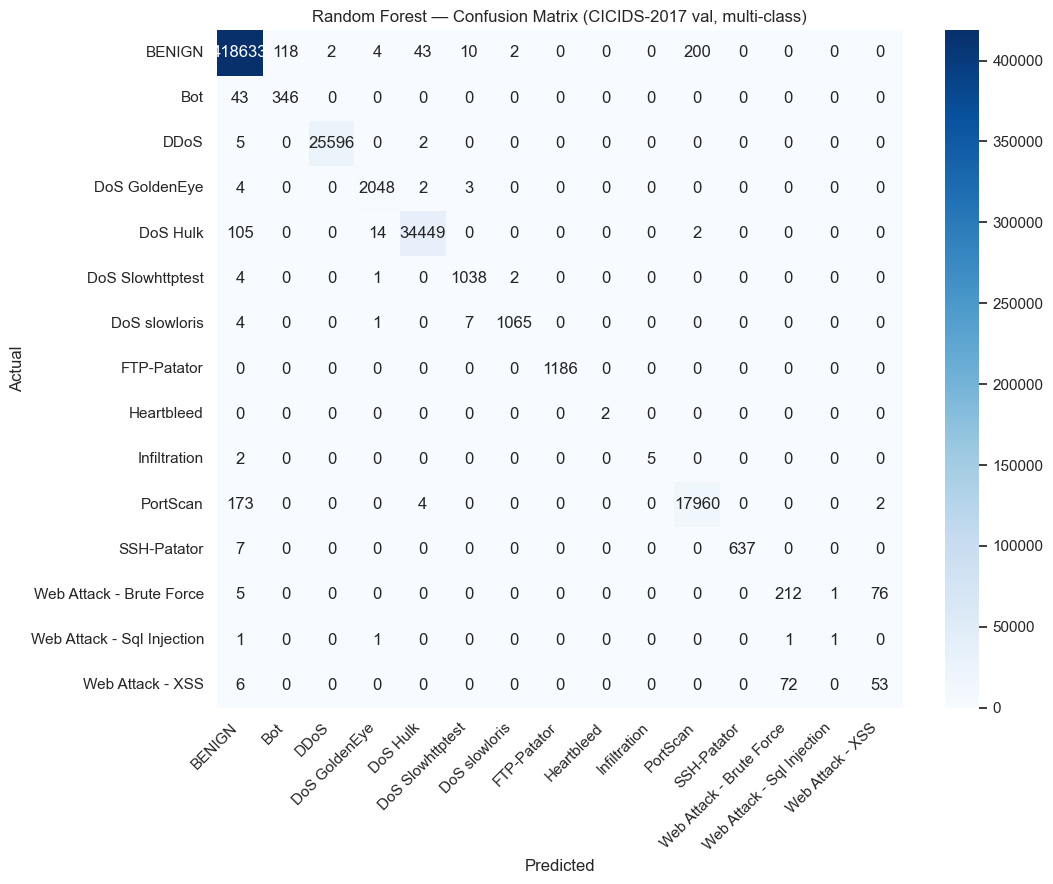

In [14]:
cm_labels = list(rf_main.classes_)
cm = confusion_matrix(y_val, predicted_label, labels=cm_labels)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=cm_labels, yticklabels=cm_labels,
    ax=ax, cbar=True,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Random Forest — Confusion Matrix (CICIDS-2017 val, multi-class)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
# Per-category recall table, same format as 01_isolation_forest.ipynb's category_recall_tuned
# (sorted worst-detected first) for direct side-by-side comparison. Two recall definitions
# shown since RF is multi-class and IF is binary:
#   - recall_exact_class: predicted_label == true label (the strict multi-class recall)
#   - recall_detected_as_attack: predicted_label != "BENIGN" (the binary "flagged as some
#     attack" recall -- this is the one directly comparable to Isolation Forest's recall,
#     which only ever says "anomaly" or "normal", never a specific category)
val_scored = val_df.copy()
val_scored["_predicted_label"] = predicted_label
val_scored["_attack_probability"] = attack_probability

attack_rows = val_scored[val_scored["Label"] != "BENIGN"].copy()
attack_rows["_exact_match"] = (attack_rows["_predicted_label"] == attack_rows["Label"]).astype(int)
attack_rows["_detected_as_attack"] = (attack_rows["_predicted_label"] != "BENIGN").astype(int)

category_recall_rf = (
    attack_rows.groupby("Label")
    .agg(
        recall_exact_class=("_exact_match", "mean"),
        recall_detected_as_attack=("_detected_as_attack", "mean"),
        n_rows=("_exact_match", "size"),
    )
    .sort_values("recall_exact_class")
)
category_recall_rf

,recall_exact_class,recall_detected_as_attack,n_rows
Label,,,
Web Attack - Sql Injection,0.250000,0.750000,4
Web Attack - XSS,0.404580,0.954198,131
Infiltration,0.714286,0.714286,7
Web Attack - Brute Force,0.721088,0.982993,294
Bot,0.889460,0.889460,389
DoS slowloris,0.988858,0.996286,1077
SSH-Patator,0.989130,0.989130,644
PortScan,0.990132,0.990463,18139
DoS Slowhttptest,0.993301,0.996172,1045


## 6. Direct comparison to Isolation Forest on the categories it failed

Isolation Forest's LOAO/main-run findings (`01_isolation_forest.ipynb`) showed near-0%
recall on **FTP-Patator, SSH-Patator, PortScan**, and weak recall on **Bot** -- the
motivating hypothesis for the whole ensemble design is that a supervised model should
recover these. Rather than hardcode Isolation Forest's per-category recall numbers (they
aren't persisted in any report CSV -- only `reports/isolation_forest_val_metrics.csv`
overall metrics and `reports/isolation_forest_loao_results.csv` per-category *zero-day*
metrics are saved), this section re-derives Isolation Forest's per-category *normal*
validation recall directly and reproducibly from
`data/features/cicids2017_isoforest_scores_val.parquet` -- the val-set anomaly
scores/predictions `01_isolation_forest.ipynb` already saved specifically "so later ensemble
members' val-set scores can be joined against it positionally" (per `CLAUDE.md`). Joining
that file to this notebook's own `val_df` by `row_index` (both loaded from the same
`cicids2017_features_val.parquet`, so row order is guaranteed identical) avoids reloading or
re-running the Isolation Forest model and keeps `01_isolation_forest.ipynb` untouched.

In [16]:
isoforest_scores_val = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_isoforest_scores_val.parquet")
assert len(isoforest_scores_val) == len(val_df), "isoforest scores file must align row-for-row with val_df"

val_with_if = val_df.copy()
val_with_if["_if_prediction"] = isoforest_scores_val["prediction"].to_numpy()  # positional join, same file/order as row_index

COMPARISON_CATEGORIES = ["FTP-Patator", "SSH-Patator", "PortScan", "Bot"]

if_recall_by_category = (
    val_with_if[val_with_if["Label"].isin(COMPARISON_CATEGORIES)]
    .groupby("Label")["_if_prediction"]
    .mean()
)

comparison_df = pd.DataFrame({
    "isolation_forest_recall": if_recall_by_category,
    "random_forest_recall_detected_as_attack": category_recall_rf.loc[COMPARISON_CATEGORIES, "recall_detected_as_attack"],
    "random_forest_recall_exact_class": category_recall_rf.loc[COMPARISON_CATEGORIES, "recall_exact_class"],
}).loc[COMPARISON_CATEGORIES]
comparison_df["improvement_pp"] = (
    (comparison_df["random_forest_recall_detected_as_attack"] - comparison_df["isolation_forest_recall"]) * 100
)
comparison_df

,isolation_forest_recall,random_forest_recall_detected_as_attack,random_forest_recall_exact_class,improvement_pp
Label,,,,
FTP-Patator,0.000000,1.000000,1.000000,100.000000
SSH-Patator,0.000000,0.989130,0.989130,98.913043
PortScan,0.002371,0.990463,0.990132,98.809196
Bot,0.023136,0.889460,0.889460,86.632391


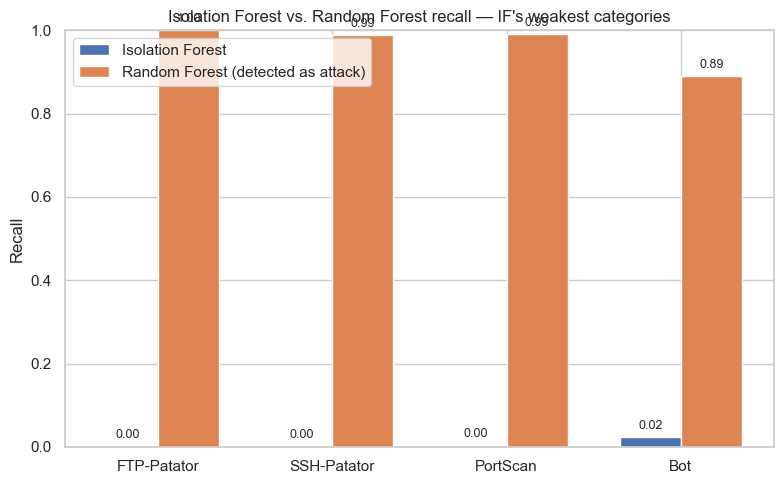

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(COMPARISON_CATEGORIES))
width = 0.35

ax.bar(x - width / 2, comparison_df["isolation_forest_recall"], width, label="Isolation Forest", color="#4C72B0")
ax.bar(x + width / 2, comparison_df["random_forest_recall_detected_as_attack"], width, label="Random Forest (detected as attack)", color="#DD8452")

ax.set_xticks(x)
ax.set_xticklabels(COMPARISON_CATEGORIES)
ax.set_ylabel("Recall")
ax.set_ylim(0, 1)
ax.set_title("Isolation Forest vs. Random Forest recall — IF's weakest categories")
ax.legend()
for i, v in enumerate(comparison_df["isolation_forest_recall"]):
    ax.text(i - width / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
for i, v in enumerate(comparison_df["random_forest_recall_detected_as_attack"]):
    ax.text(i + width / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

### Headline overall-metrics comparison

`reports/isolation_forest_val_metrics.csv`'s `current_contamination_tuned` row (Isolation
Forest's final tuned binary metrics) against Random Forest's binary roll-up from §5.

In [18]:
if_val_metrics = pd.read_csv(REPORTS_DIR / "isolation_forest_val_metrics.csv")
if_tuned_row = if_val_metrics[if_val_metrics["status"] == "current_contamination_tuned"].iloc[0]

headline_comparison_df = pd.DataFrame([
    {"model": "Isolation Forest (tuned)", "precision": if_tuned_row["precision"], "recall": if_tuned_row["recall"],
     "f1": if_tuned_row["f1"], "auc_roc": if_tuned_row["auc_roc"]},
    {"model": "Random Forest (binary roll-up)", "precision": binary_precision, "recall": binary_recall,
     "f1": binary_f1, "auc_roc": binary_auc_roc},
])
headline_comparison_df

,model,precision,recall,f1,auc_roc
0,Isolation Forest (tuned),0.529191,0.555785,0.542162,0.728624
1,Random Forest (binary roll-up),0.995550,0.995784,0.995667,0.999776


## 7. Zero-day (LOAO) evaluation

Same 10 categories, same fold structure as `01_isolation_forest.ipynb` §6: for each held-out
category, retrain on that category's LOAO training set (`preprocess_pipeline.py`'s
`build_loao_split` output -- all BENIGN except a held-out 20% + every attack category except
the one held out) and evaluate on the zero-day test set (the held-out BENIGN slice + only
the held-out category).

**LOAO + SMOTE design decision (flagging this explicitly, not assuming):** confirmed below
that the LOAO parquet files are raw/unresampled, straight out of `preprocess_pipeline.py`
(natural per-category counts, no capped-SMOTE row inflation, no CTI columns -- they predate
`feature_extractor.py` entirely, same as Isolation Forest's LOAO folds used). Isolation
Forest's LOAO folds correctly leave this alone, since it's unsupervised and never uses
`Label` for training, so class balance is irrelevant to it. Random Forest is different: its
*main* model above trains on capped-SMOTE-resampled data specifically because raw class
imbalance would otherwise bias a supervised classifier toward `BENIGN`/flood categories. That
same imbalance is present in every LOAO fold's training set (e.g. `BENIGN` 1,676,045 vs.
`Heartbleed` 11 in the `loao_bot_train.parquet` fold) -- leaving it unresampled here while
resampling it in §3 would make the LOAO folds internally inconsistent with how this
notebook's own main model is trained, for no principled reason. **Decision: apply the same
capped-SMOTE strategy (`min(majority, 20x, 50_000)`, reusing the exact constants/formula
from `src/feature_extractor.py` and this notebook's §1 config) to each LOAO fold's training
set before fitting.** This does not touch the held-out zero-day category at all (SMOTE only
resamples classes present in the fold's `y_train`, and the held-out category is absent from
it by construction), so it doesn't weaken the zero-day test in any way -- it only rebalances
the *known* classes each fold trains on, matching §3's regime.

In [19]:
def impute_sentinels_train_only(train_df_fold, test_df_fold, sentinel_cols):
    train_df_fold = train_df_fold.copy()
    test_df_fold = test_df_fold.copy()
    for c in sentinel_cols:
        median = train_df_fold[c].median(skipna=True)
        train_df_fold[c] = train_df_fold[c].fillna(median)
        test_df_fold[c] = test_df_fold[c].fillna(median)
    return train_df_fold, test_df_fold


def build_smote_sampling_strategy(y):
    # Mirrors src/feature_extractor.py's build_smote_sampling_strategy exactly.
    counts = pd.Series(y).value_counts()
    majority_count = int(counts.max())
    strategy = {}
    for cls, n in counts.items():
        n = int(n)
        if n >= SMOTE_FLAT_CAP:
            continue
        target = min(majority_count, n * SMOTE_TARGET_MULTIPLIER, SMOTE_FLAT_CAP)
        if target > n:
            strategy[cls] = target
    return strategy


def apply_smote_loao(X, y):
    strategy = build_smote_sampling_strategy(y)
    if not strategy:
        return X, y, False
    min_class_n = min(int((pd.Series(y) == cls).sum()) for cls in strategy)
    k_neighbors = max(1, min(5, min_class_n - 1))
    smote = SMOTE(sampling_strategy=strategy, k_neighbors=k_neighbors, random_state=SMOTE_RANDOM_STATE)
    X_res, y_res = smote.fit_resample(X, y)
    return X_res, y_res, True


CATEGORIES = [
    ("DoS Hulk", "dos_hulk"),
    ("PortScan", "portscan"),
    ("DDoS", "ddos"),
    ("DoS GoldenEye", "dos_goldeneye"),
    ("FTP-Patator", "ftp_patator"),
    ("SSH-Patator", "ssh_patator"),
    ("DoS slowloris", "dos_slowloris"),
    ("DoS Slowhttptest", "dos_slowhttptest"),
    ("Bot", "bot"),
    ("Web Attack - Brute Force", "web_attack_brute_force"),
]

SENTINEL_COLS_LOAO = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]

# Confirm the raw/unresampled premise before relying on it.
_sample_loao = pd.read_parquet(LOAO_DIR / "loao_bot_train.parquet")
print("loao_bot_train.parquet shape:", _sample_loao.shape, "  columns:", len(_sample_loao.columns))
print(_sample_loao["Label"].value_counts())
print("\n-> raw/unresampled, natural per-category counts (matches preprocess_pipeline.py's LOAO output, "
      "not feature_extractor.py's SMOTE/CTI-joined output). Confirms the design decision above.")

loao_bot_train.parquet shape: (2099838, 79)   columns: 79
Label
BENIGN                        1676045
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

-> raw/unresampled, natural per-category counts (matches preprocess_pipeline.py's LOAO output, not feature_extractor.py's SMOTE/CTI-joined output). Confirms the design decision above.


In [20]:
loao_results = []

for display_name, slug in CATEGORIES:
    loao_train_df = pd.read_parquet(LOAO_DIR / f"loao_{slug}_train.parquet")
    loao_test_df = pd.read_parquet(LOAO_DIR / f"loao_{slug}_zeroday_test.parquet")

    loao_train_df, loao_test_df = impute_sentinels_train_only(loao_train_df, loao_test_df, SENTINEL_COLS_LOAO)

    loao_feature_cols = select_feature_columns(loao_train_df)
    X_loao_train = loao_train_df[loao_feature_cols].to_numpy(dtype=np.float64)
    y_loao_train = loao_train_df["Label"].to_numpy()
    X_loao_test = loao_test_df[loao_feature_cols].to_numpy(dtype=np.float64)

    X_loao_train_res, y_loao_train_res, smote_applied = apply_smote_loao(X_loao_train, y_loao_train)

    loao_model = RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        max_depth=MAX_DEPTH,
        class_weight=CLASS_WEIGHT,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )
    loao_model.fit(X_loao_train_res, y_loao_train_res)

    loao_pred_label = loao_model.predict(X_loao_test)
    # The held-out category was never in training, so the classifier cannot predict its
    # exact name -- "detected" here means flagged as *some* non-BENIGN class, the same
    # zero-day-blindness framing the Isolation Forest LOAO section uses.
    loao_pred_attack = (loao_pred_label != "BENIGN").astype(int)
    loao_y_true = (loao_test_df["Label"] != "BENIGN").astype(int).to_numpy()

    tp = int(((loao_pred_attack == 1) & (loao_y_true == 1)).sum())
    fn = int(((loao_pred_attack == 0) & (loao_y_true == 1)).sum())
    fp = int(((loao_pred_attack == 1) & (loao_y_true == 0)).sum())
    tn = int(((loao_pred_attack == 0) & (loao_y_true == 0)).sum())

    fold_recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    fold_fpr = fp / (fp + tn) if (fp + tn) > 0 else float("nan")

    loao_results.append({
        "category": display_name,
        "recall": fold_recall,
        "fpr": fold_fpr,
        "n_test_rows": len(loao_test_df),
        "n_attack_rows": int(loao_y_true.sum()),
        "n_benign_rows": int((loao_y_true == 0).sum()),
        "smote_applied": smote_applied,
        "train_rows_after_smote": len(y_loao_train_res),
    })

    print(f"{display_name:30s}  recall={fold_recall:.4f}  fpr={fold_fpr:.4f}  "
          f"n_test={len(loao_test_df)}  smote_applied={smote_applied}  train_rows={len(y_loao_train_res):,}")

loao_summary_df = pd.DataFrame(loao_results).sort_values("recall").reset_index(drop=True)

DoS Hulk                        recall=0.0116  fpr=0.0008  n_test=591858  smote_applied=True  train_rows=2,227,513


PortScan                        recall=0.0017  fpr=0.0005  n_test=509706  smote_applied=True  train_rows=2,309,665


DDoS                            recall=0.6166  fpr=0.0010  n_test=547026  smote_applied=True  train_rows=2,272,345


DoS GoldenEye                   recall=0.1691  fpr=0.0010  n_test=429298  smote_applied=True  train_rows=2,350,359


FTP-Patator                     recall=0.3128  fpr=0.0010  n_test=424943  smote_applied=True  train_rows=2,350,359


SSH-Patator                     recall=0.0065  fpr=0.0010  n_test=422231  smote_applied=True  train_rows=2,350,359


DoS slowloris                   recall=0.6882  fpr=0.0010  n_test=424397  smote_applied=True  train_rows=2,350,359


DoS Slowhttptest                recall=0.1966  fpr=0.0010  n_test=424240  smote_applied=True  train_rows=2,350,359


Bot                             recall=0.0000  fpr=0.0006  n_test=420960  smote_applied=True  train_rows=2,361,399


Web Attack - Brute Force        recall=0.8531  fpr=0.0010  n_test=420482  smote_applied=True  train_rows=2,370,959


In [21]:
loao_summary_df

,category,recall,fpr,n_test_rows,n_attack_rows,n_benign_rows,smote_applied,train_rows_after_smote
0,Bot,0.000000,0.000628,420960,1948,419012,True,2361399
1,PortScan,0.001665,0.000537,509706,90694,419012,True,2309665
2,SSH-Patator,0.006524,0.000983,422231,3219,419012,True,2350359
3,DoS Hulk,0.011583,0.000814,591858,172846,419012,True,2227513
4,DoS GoldenEye,0.169065,0.000969,429298,10286,419012,True,2350359
5,DoS Slowhttptest,0.196634,0.000964,424240,5228,419012,True,2350359
6,FTP-Patator,0.312763,0.000978,424943,5931,419012,True,2350359
7,DDoS,0.616565,0.000962,547026,128014,419012,True,2272345
8,DoS slowloris,0.688208,0.000976,424397,5385,419012,True,2350359
9,Web Attack - Brute Force,0.853061,0.000969,420482,1470,419012,True,2370959


### LOAO comparison: Isolation Forest vs. Random Forest

Isolation Forest's LOAO pattern (`reports/isolation_forest_loao_results.csv`,
`current_contamination_tuned` rows) tracked its *in-dataset* per-category weakness almost
exactly: it struggled on the same low-and-slow categories (FTP-Patator, SSH-Patator,
PortScan, Bot) whether or not that category was held out, because its blind spot is about
the attack pattern itself looking normal, not about having seen the label before.

Random Forest is expected to show close to the **opposite** pattern: strong in-dataset
per-category recall (§5/§6) for most categories, but **the held-out category specifically**
should be the one RF struggles with in LOAO, precisely *because* it was excluded from
training -- true zero-day blindness, a failure mode that doesn't exist for an unsupervised
model like Isolation Forest.

In [22]:
if_loao = pd.read_csv(REPORTS_DIR / "isolation_forest_loao_results.csv")
if_loao_tuned = if_loao[if_loao["status"] == "current_contamination_tuned"].set_index("category")

loao_comparison_df = pd.DataFrame({
    "isolation_forest_recall": if_loao_tuned["recall"],
    "isolation_forest_fpr": if_loao_tuned["fpr"],
    "random_forest_recall": loao_summary_df.set_index("category")["recall"],
    "random_forest_fpr": loao_summary_df.set_index("category")["fpr"],
}).loc[[c for c, _ in CATEGORIES]]
loao_comparison_df["recall_diff_rf_minus_if"] = (
    loao_comparison_df["random_forest_recall"] - loao_comparison_df["isolation_forest_recall"]
)
loao_comparison_df.sort_values("random_forest_recall")

,isolation_forest_recall,isolation_forest_fpr,random_forest_recall,random_forest_fpr,recall_diff_rf_minus_if
category,,,,,
Bot,0.023101,0.121629,0.000000,0.000628,-0.023101
PortScan,0.002018,0.109562,0.001665,0.000537,-0.000353
SSH-Patator,0.003417,0.121839,0.006524,0.000983,0.003107
DoS Hulk,0.900414,0.169387,0.011583,0.000814,-0.888832
DoS GoldenEye,0.729827,0.117001,0.169065,0.000969,-0.560762
DoS Slowhttptest,0.846978,0.119419,0.196634,0.000964,-0.650344
FTP-Patator,0.000843,0.115789,0.312763,0.000978,0.311920
DDoS,0.634806,0.132316,0.616565,0.000962,-0.018240
DoS slowloris,0.613185,0.117608,0.688208,0.000976,0.075023


## 8. Save the model + results

In [23]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODELS_DIR / "random_forest.pkl"
joblib.dump(rf_main, model_path)
print("Saved main model to", model_path)

Saved main model to E:\thesis\models\random_forest.pkl


In [24]:
val_metrics_rows = [
    {"scope": "binary_rollup", "precision": binary_precision, "recall": binary_recall,
     "f1": binary_f1, "auc_roc": binary_auc_roc},
    {"scope": "multiclass_macro", "precision": macro_precision, "recall": macro_recall,
     "f1": macro_f1, "auc_roc": macro_auc_ovr},
]
val_metrics_summary_df = pd.DataFrame(val_metrics_rows)

per_category_out_df = category_recall_rf.copy()
per_category_out_df["auc_roc_ovr"] = per_class_auc_series.reindex(per_category_out_df.index)
per_category_out_df = per_category_out_df.reset_index().rename(columns={"Label": "category"})

val_metrics_path = REPORTS_DIR / "random_forest_val_metrics.csv"
with open(val_metrics_path, "w", encoding="utf-8") as f:
    f.write("# overall (binary roll-up + multiclass macro)\n")
    val_metrics_summary_df.to_csv(f, index=False)
    f.write("\n# per-category (attack classes only)\n")
    per_category_out_df.to_csv(f, index=False)

print("Saved val-set metrics to", val_metrics_path)
val_metrics_summary_df

Saved val-set metrics to E:\thesis\reports\random_forest_val_metrics.csv


,scope,precision,recall,f1,auc_roc
0,binary_rollup,0.995550,0.995784,0.995667,0.999776
1,multiclass_macro,0.889853,0.862119,0.871182,0.999078


In [25]:
loao_csv_path = REPORTS_DIR / "random_forest_loao_results.csv"
loao_summary_df.to_csv(loao_csv_path, index=False)
print("Saved LOAO summary to", loao_csv_path)

Saved LOAO summary to E:\thesis\reports\random_forest_loao_results.csv


In [26]:
# row_index: position within cicids2017_features_val.parquet (0..N-1), same convention as
# cicids2017_isoforest_scores_val.parquet, so this can be joined positionally against
# Isolation Forest/Autoencoder scores on the same val split later in the Fusion Layer.
proba_cols = {f"proba_{cls}": predicted_proba[:, i] for i, cls in enumerate(rf_main.classes_)}

rf_val_scores_df = pd.DataFrame({
    "row_index": val_df.index.to_numpy(),
    "predicted_label": predicted_label,
    "prediction": pred_binary,       # 1 = flagged as some attack class, 0 = BENIGN
    "attack_probability": attack_probability,  # 1 - P(BENIGN), analogous to IF's anomaly_score
    **proba_cols,
})

rf_val_scores_path = DATA_FEATURES_DIR / "cicids2017_rf_scores_val.parquet"
rf_val_scores_df.to_parquet(rf_val_scores_path, index=False)
print("Saved val-set scores to", rf_val_scores_path)
rf_val_scores_df.head()

Saved val-set scores to E:\thesis\data\features\cicids2017_rf_scores_val.parquet


,row_index,predicted_label,prediction,attack_probability,proba_BENIGN,proba_Bot,proba_DDoS,proba_DoS GoldenEye,proba_DoS Hulk,proba_DoS Slowhttptest,proba_DoS slowloris,proba_FTP-Patator,proba_Heartbleed,proba_Infiltration,proba_PortScan,proba_SSH-Patator,proba_Web Attack - Brute Force,proba_Web Attack - Sql Injection,proba_Web Attack - XSS
0,0,DoS Hulk,1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,BENIGN,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,BENIGN,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,BENIGN,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,BENIGN,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
